# ☀️ Exercise 2 — Solar plant in Malta · **SOLUTION (teacher)**
Same notebook as the students', with the blanks filled and a few teacher comments (marked 👨‍🏫). The rescue cell is omitted here.

**Expected results ✅ (seed 42)**

| | MAE (MW) | RMSE (MW) | nMAE (%) |
|---|---|---|---|
| Validation (Apr–Jun 2024) — XGBoost | 0.112 | 0.206 | 1.31 |
| Validation — baseline (yesterday) | 0.400 | 0.971 | 4.70 |
| **Test (Jul–Dec 2024) — XGBoost** | **0.101** | **0.182** | **1.19** |
| Test — baseline | 0.262 | 0.682 | 3.08 |

In [1]:
# ===== SETUP: run this cell first. Do not change it. =====
%pip install -q shap

import os, random, json, warnings
import numpy as np                      # maths
import pandas as pd                     # tables (like Excel, but in Python)
import matplotlib.pyplot as plt         # plots
import joblib                           # to save the trained model
import shap                             # explainable AI
from xgboost import XGBRegressor        # the machine learning model (NEW: Exercise 1 used Random Forest)
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")
SEED = 42                               # fixed random seed: everybody gets the same numbers
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
plt.rcParams["figure.figsize"] = (10, 4)
print("Setup done.")

Setup done.


In [2]:
# ===== LOAD THE TRAINING DATA (given: do not change) =====
TRAIN_URL = "https://raw.githubusercontent.com/mariocaruso96/MENA/main/exercise_2_train.csv"
pv_raw = pd.read_csv(TRAIN_URL)

print("Rows and columns:", pv_raw.shape)
pv_raw.head()

Rows and columns: (13188, 11)


,timestamp,month,day_of_week,is_holiday,solar_elevation_deg,ghi_forecast_wm2,cloud_cover_forecast_pct,temperature_c,wind_speed_ms,pv_power_lag_24h_mw,pv_power_mw
0,2023-01-01 00:00,1,6,1,-76.1,0.0,46.0,11.3,5.5,NaN,-0.018
1,2023-01-01 01:00,1,6,1,-67.6,0.0,42.0,10.3,5.4,NaN,-0.021
2,2023-01-01 02:00,1,6,1,-56.2,0.0,33.0,9.9,5.7,NaN,-0.015
3,2023-01-01 03:00,1,6,1,-44.2,0.0,40.0,10.1,6.1,NaN,-0.015
4,2023-01-01 04:00,1,6,1,-32.0,0.0,43.0,11.3,6.4,NaN,-0.022


## 📊 The data: what is in each column?

Each row is **one hour** of a fictional solar plant in Malta (**maximum output 8.5 MW**). The table goes from **1 January 2023 to 30 June 2024** (18 months, one row per hour). The goal is to predict the last column, `pv_power_mw`, using the other columns.

⚠️ The columns marked *forecast* are **weather forecasts**, not measurements. They are known **before** the hour starts, so they can be used to predict. Like all forecasts, they contain small errors.

| Column | What it is | Unit / values |
|---|---|---|
| `timestamp` | Date and hour of the row | e.g. `2023-01-01 14:00` |
| `month` | Month of the year | 1 to 12 |
| `day_of_week` | Day of the week | 0 = Monday … 6 = Sunday |
| `is_holiday` | Public holiday in Malta? | 0 = no, 1 = yes |
| `solar_elevation_deg` | Height of the sun above the horizon. **Negative = night** | degrees (about −76 to +76) |
| `ghi_forecast_wm2` | **Forecast** of the sun power reaching the ground (*Global Horizontal Irradiance*: direct + diffuse light on a horizontal surface). The main driver of solar production | W/m² (0 at night, about 1000 at clear summer noon) |
| `cloud_cover_forecast_pct` | **Forecast** of the share of the sky covered by clouds | % (0 = clear, 100 = fully covered) |
| `temperature_c` | Air temperature | °C |
| `wind_speed_ms` | Wind speed (wind cools the panels a little) | m/s |
| `pv_power_lag_24h_mw` | Power produced **at the same hour yesterday** (known when we make the forecast) | MW |
| **`pv_power_mw`** | **🎯 TARGET: power produced by the plant in that hour** | MW (0 at night, maximum 8.5) |

### 💡 Things to know before you start
- **Zero at night is normal.** The sun is down, so the plant produces nothing (you may see tiny negative values like −0.02 MW: the plant's own consumption).
- **The plant has a maximum of 8.5 MW.** Above a certain amount of sun the power stops growing because the inverters limit it. This is real physics, not an error.
- **The data is not perfect.** Like real data, the training table has **duplicated rows**, **missing values** and **impossible values** (a 8.5 MW plant cannot produce 57 MW, or −5 MW). Finding and fixing them is part of the exercise.
- **Not every column is useful.** The sun does not know if it is Sunday: some columns may matter very little. SHAP will tell you.
- **The last 6 months are hidden** (1 July → 31 December 2024). Your instructor will give them to you at the end for the final test.

---
# Step 1 — Order the data, remove duplicates, fill the gaps  *(10 min)*
📘 *Data quality: garbage in, garbage out.* A time series must be **in order**, with **one row per hour**.

First look at the table (run the cell). Notice the **missing values** (temperature, power) and the **minimum / maximum** of the power: a plant of 8.5 MW cannot produce 57 MW, or −5 MW!

In [3]:
# LOOK at the table (given: just run it)
print(pv_raw.dtypes)
print()
print("Missing values per column:")
print(pv_raw.isna().sum())
print()
pv_raw.describe().T[["min", "mean", "max"]]

timestamp                    object
month                         int64
day_of_week                   int64
is_holiday                    int64
solar_elevation_deg         float64
ghi_forecast_wm2            float64
cloud_cover_forecast_pct    float64
temperature_c               float64
wind_speed_ms               float64
pv_power_lag_24h_mw         float64
pv_power_mw                 float64
dtype: object

Missing values per column:
timestamp                     0
month                         0
day_of_week                   0
is_holiday                    0
solar_elevation_deg           0
ghi_forecast_wm2              0
cloud_cover_forecast_pct      0
temperature_c               130
wind_speed_ms                 0
pv_power_lag_24h_mw          24
pv_power_mw                 191
dtype: int64



,min,mean,max
month,1.000,5.517516,12.000
day_of_week,0.000,3.006749,6.000
is_holiday,0.000,0.040340,1.000
solar_elevation_deg,-76.200,0.866052,76.400
ghi_forecast_wm2,0.000,228.564832,1358.000
cloud_cover_forecast_pct,0.000,35.319988,100.000
temperature_c,4.400,20.290098,38.000
wind_speed_ms,0.200,4.727244,12.200
pv_power_lag_24h_mw,-0.037,2.257593,8.500
pv_power_mw,-5.000,2.308299,57.133


👨‍🏫 Expected: 13,188 rows; 130 missing temperatures, 191 missing power, 24 missing lag (the first day has no "yesterday"); power from −5 to ~57 MW. The **60 duplicates** are rows appended at the end of the file, so the file is **not in time order**.

In [5]:
# STEP 1
df = pv_raw.copy()                                          # work on a copy

df["timestamp"] = pd.to_datetime(df["timestamp"])           # text -> real date and time

df = df.sort_values("timestamp")                            # 1) oldest hour first
df = df.drop_duplicates(subset="timestamp", keep="first")   # 2) one row per hour
df = df.reset_index(drop=True)

df["hour"] = df["timestamp"].dt.hour                    # new column: hour of the day (0-23)

# 3) fill the missing temperatures with a straight line between the neighbouring hours
df["temperature_c"] = df["temperature_c"].interpolate()

In [6]:
# CHECK (given)
print("Rows:", len(df), "   (expected 13128)")
print("Time in order?", df["timestamp"].is_monotonic_increasing, "   (expected True)")
print("Missing temperatures:", df["temperature_c"].isna().sum(), "   (expected 0)")

Rows: 13128    (expected 13128)
Time in order? True    (expected True)
Missing temperatures: 0    (expected 0)


---
# Step 2 — Plots and outliers  *(10 min)*
Run the plots and **look**:
1. **Left:** most hours are 0 (the nights). But there are a few **huge** values (up to ~57 MW) and some **negative** ones. Impossible!
2. **Middle:** more sun = more power, a nice line, with a **flat ceiling at 8.5 MW** (the inverters limit the plant: that is real, not an error). The dots far above the line are outliers.
3. **Right:** the plant works from ~6:00 to ~19:00 and sleeps at night. ✅ Zero at night is **normal**.

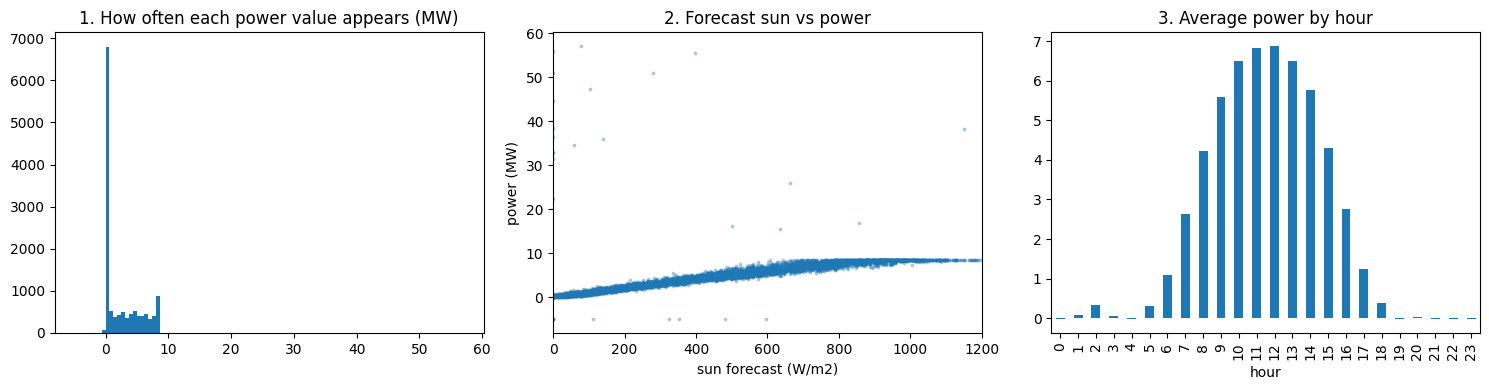

In [7]:
# PLOTS (given: just run it and LOOK)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(df["pv_power_mw"].dropna(), bins=100)
axes[0].set_title("1. How often each power value appears (MW)")

axes[1].scatter(df["ghi_forecast_wm2"], df["pv_power_mw"], s=3, alpha=0.3)
axes[1].set_xlim(0, 1200)
axes[1].set_title("2. Forecast sun vs power")
axes[1].set_xlabel("sun forecast (W/m2)"); axes[1].set_ylabel("power (MW)")

df.groupby("hour")["pv_power_mw"].mean().plot(kind="bar", ax=axes[2], title="3. Average power by hour")

plt.tight_layout(); plt.show()

👨‍🏫 **Trap:** the ceiling at 8.5 MW and the zeros at night are REAL. An AI that suggests an IQR rule or "drop power ≤ 0" would damage the model (summer-noon values look like outliers; nights are 0). Test with the wrong rule: nMAE rises from 1.2 % to ≈ 2.2 %.

In [8]:
# STEP 2 - complete the blanks ___
# ONE rule for the outliers: power above the plant maximum (8.5 MW) OR clearly negative (below -0.1 MW)
is_outlier = (df["pv_power_mw"] > 8.5) | (df["pv_power_mw"] < -0.1)
print("Outliers found:", is_outlier.sum())

df.loc[is_outlier, "pv_power_mw"] = np.nan                  # turn them into "missing"

# We never invent the TARGET: remove the rows where the power is missing
df = df.dropna(subset=["pv_power_mw", "pv_power_lag_24h_mw"])
df = df.reset_index(drop=True)
print("Rows left:", len(df))

Outliers found: 30
Rows left: 12883


In [9]:
# CHECK (given)
print("Rows left:", len(df), "   (expected about 12883)")
print("Power from", df["pv_power_mw"].min(), "to", df["pv_power_mw"].max(), "MW   (expected about -0.04 to 8.5)")
print("Missing values left:", int(df.isna().sum().sum()), "   (expected 0)")

Rows left: 12883    (expected about 12883)
Power from -0.037 to 8.5 MW   (expected about -0.04 to 8.5)
Missing values left: 0    (expected 0)


---
# Step 3 — Split in time, train XGBoost, measure the error  *(10 min)*
📘 *Train / validation / test.* The model learns on **training** and is checked on **validation** (data it has never seen). In a time series we **never** split randomly: training = the past, validation = the most recent months.

📘 *Baseline.* A model is useful only if it beats a simple rule. Our baseline: **"the power will be the same as yesterday at this hour"**.

In [10]:
# STEP 3 - complete the blanks ___
# 3.1 Split IN TIME ORDER: learn on the past, check on the most recent months
SPLIT_DATE = "2024-04-01"
train_part = df[df["timestamp"] < SPLIT_DATE]
val_part   = df[df["timestamp"] >= SPLIT_DATE]

# 3.2 Inputs (features) = all columns except the time stamp and the target
feature_cols = [c for c in df.columns if c not in ["timestamp", "pv_power_mw"]]
print("Features:", feature_cols)

X_train = train_part[feature_cols];  y_train = train_part["pv_power_mw"]
X_val   = val_part[feature_cols];    y_val   = val_part["pv_power_mw"]

# 3.3 Train XGBoost (given)
model = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=5,
                     subsample=0.8, colsample_bytree=0.8, random_state=SEED, n_jobs=1)
model.fit(X_train, y_train)

# 3.4 Predict on the validation months (a plant cannot produce less than 0 or more than 8.5 MW)
pred_val = model.predict(X_val)
pred_val = np.clip(pred_val, 0, 8.5)

Features: ['month', 'day_of_week', 'is_holiday', 'solar_elevation_deg', 'ghi_forecast_wm2', 'cloud_cover_forecast_pct', 'temperature_c', 'wind_speed_ms', 'pv_power_lag_24h_mw', 'hour']


VALIDATION            MAE (MW)   RMSE (MW)   nMAE (%)
XGBoost model            0.112       0.206       1.31
Baseline (yesterday)     0.400       0.971       4.70


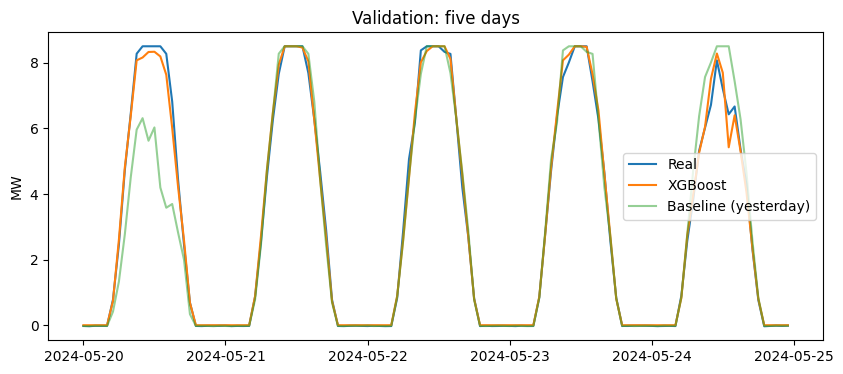

In [11]:
# ERRORS (given: just run it)
y = y_val.values
mae  = mean_absolute_error(y, pred_val)                   # average error, in MW
rmse = np.sqrt(mean_squared_error(y, pred_val))           # like MAE, but big errors count more
nmae = mae / 8.5 * 100                                    # MAE as % of the plant size

baseline = val_part["pv_power_lag_24h_mw"].values         # baseline = "same hour yesterday"
mae_b  = mean_absolute_error(y, baseline)
rmse_b = np.sqrt(mean_squared_error(y, baseline))
nmae_b = mae_b / 8.5 * 100

print("VALIDATION            MAE (MW)   RMSE (MW)   nMAE (%)")
print(f"XGBoost model         {mae:8.3f}   {rmse:9.3f}   {nmae:8.2f}")
print(f"Baseline (yesterday)  {mae_b:8.3f}   {rmse_b:9.3f}   {nmae_b:8.2f}")

five = (val_part["timestamp"] >= "2024-05-20") & (val_part["timestamp"] < "2024-05-25")
plt.plot(val_part.loc[five, "timestamp"], y_val[five], label="Real")
plt.plot(val_part.loc[five, "timestamp"], pred_val[five.values], label="XGBoost")
plt.plot(val_part.loc[five, "timestamp"], val_part.loc[five, "pv_power_lag_24h_mw"], label="Baseline (yesterday)", alpha=0.5)
plt.legend(); plt.ylabel("MW"); plt.title("Validation: five days"); plt.show()

👨‍🏫 Expected: XGBoost nMAE ≈ 1.3 %, the baseline ≈ 4.7 % (yesterday's clouds ≠ today's). The validation has only Apr–Jun: no autumn/winter.

---
# Step 4 — SHAP: what does the model look at?  *(8 min)*
📘 *Explainable AI.* SHAP tells how much **each feature pushed each prediction up or down**. In the plot: **one dot = one hour**, **colour** = value of the feature (red = high, blue = low), **left/right** = the prediction goes down/up.

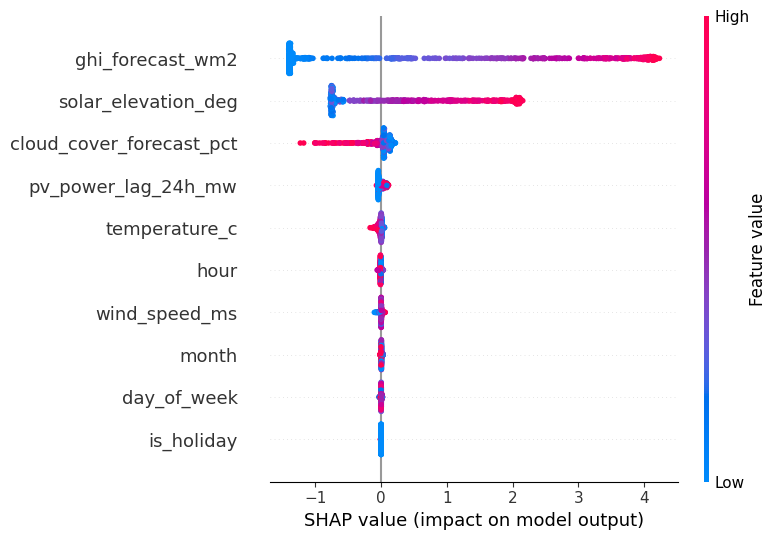

In [12]:
# STEP 4 - complete the blank ___
explainer = shap.TreeExplainer(model)

X_sample = X_val.sample(800, random_state=SEED)             # 800 hours are enough (and fast)
shap_values = explainer.shap_values(X_sample)

shap.summary_plot(shap_values, X_sample)                # one dot = one hour. Red = high value of the feature.

👨‍🏫 Top: `ghi_forecast_wm2` (by far) and `solar_elevation_deg`; then cloud cover. Near zero: `day_of_week`, `is_holiday`, `wind_speed_ms`, `month`, `hour` (redundant with the sun height). Temperature is small, with a *negative* effect in sunny hours (hot panels lose ≈ 0.4 %/°C). Reminder: SHAP is not causality.

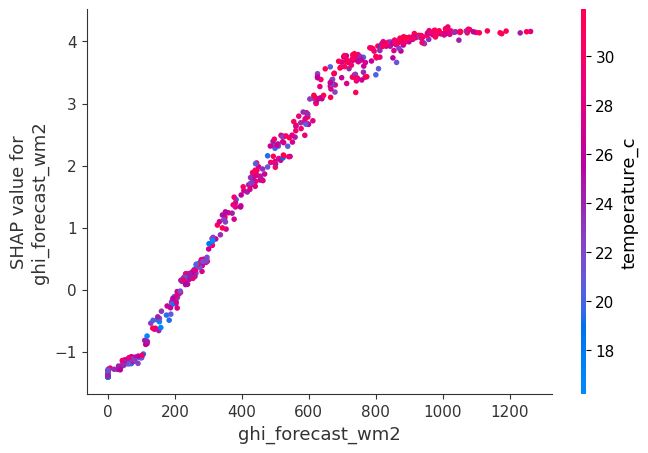

In [13]:
# BONUS: how do sun and temperature work together? (SHAP dependence plot)
shap.dependence_plot("ghi_forecast_wm2", shap_values, X_sample, interaction_index="temperature_c")

---
# Step 5 — Save the model and take the final exam  *(7 min)*
📘 *Deployment and inference.* We **save** the final model, and the names of the features in the right order. Then we load them again and use them on **brand new data** (1 Jul → 31 Dec 2024), exactly like a real service would.

**Fill the blanks ___ in the next cell:** the target for the training is **y_all**; the list of names to save is **feature_cols**.

In [14]:
# STEP 5 (part 1) - complete the blanks ___
# Retrain the same model on ALL the clean data, so it also knows the latest months
X_all = df[feature_cols]
y_all = df["pv_power_mw"]

model_final = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=5,
                           subsample=0.8, colsample_bytree=0.8, random_state=SEED, n_jobs=1)
model_final.fit(X_all, y_all)

joblib.dump(model_final, "pv_model.joblib")                 # save the model
with open("pv_feature_cols.json", "w") as f:                 # save the names of the features
    json.dump(feature_cols, f)
print("Saved: pv_model.joblib and pv_feature_cols.json")

Saved: pv_model.joblib and pv_feature_cols.json


TEST                  MAE (MW)   RMSE (MW)   nMAE (%)
XGBoost model            0.101       0.182       1.19
Baseline (yesterday)     0.262       0.682       3.08


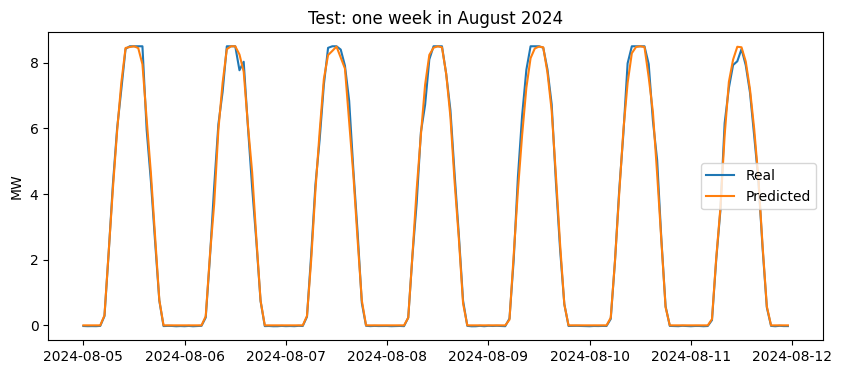

In [15]:
# STEP 5 (part 2) - THE TEST. Run it only when the instructor says so.
TEST_URL = "https://raw.githubusercontent.com/mariocaruso96/MENA/main/exercise_2_test.csv"

# load what we saved
model_loaded = joblib.load("pv_model.joblib")
model_loaded.set_params(n_jobs=1)
with open("pv_feature_cols.json") as f:
    feature_cols_loaded = json.load(f)

# load the test data and prepare it EXACTLY like the training data
test = pd.read_csv(TEST_URL)
test["timestamp"] = pd.to_datetime(test["timestamp"])
test = test.sort_values("timestamp").reset_index(drop=True)
test["hour"] = test["timestamp"].dt.hour

# predict (same columns, same order as in training)
pred_test = model_loaded.predict(test[feature_cols_loaded])
pred_test = np.clip(pred_test, 0, 8.5)

# errors
y = test["pv_power_mw"].values
mae  = mean_absolute_error(y, pred_test)
rmse = np.sqrt(mean_squared_error(y, pred_test))
nmae = mae / 8.5 * 100

baseline = test["pv_power_lag_24h_mw"].values
mae_b  = mean_absolute_error(y, baseline)
rmse_b = np.sqrt(mean_squared_error(y, baseline))
nmae_b = mae_b / 8.5 * 100

print("TEST                  MAE (MW)   RMSE (MW)   nMAE (%)")
print(f"XGBoost model         {mae:8.3f}   {rmse:9.3f}   {nmae:8.2f}")
print(f"Baseline (yesterday)  {mae_b:8.3f}   {rmse_b:9.3f}   {nmae_b:8.2f}")

week = (test["timestamp"] >= "2024-08-05") & (test["timestamp"] < "2024-08-12")
plt.plot(test.loc[week, "timestamp"], y[week.values], label="Real")
plt.plot(test.loc[week, "timestamp"], pred_test[week.values], label="Predicted")
plt.legend(); plt.ylabel("MW"); plt.title("Test: one week in August 2024"); plt.show()

👨‍🏫 Expected test: MAE ≈ 0.10 MW, nMAE ≈ 1.2 %; baseline ≈ 3.1 %. Test ≈ validation, so the validation was trustworthy. For discussion: what would you monitor (panel degradation ≈ 0.5 %/year, inverter outages, forecast quality, heat waves)? Hourly data hides the fast ramps caused by clouds.